# Tool Instalation

In [ ]:
# Install for EDA fast
!pip install -q ydata-profiling
!pip install -q "numpy<=2.3.3" # Conflict libraries

# Restart the Colan runtime
import os
os.kill(os.getpid(), 9)



In [22]:
from google.colab import files

import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

from ydata_profiling import ProfileReport

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from sklearn.metrics import PredictionErrorDisplay
from sklearn.inspection import permutation_importance

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV


# Upload data

In [2]:
# Open file explorer
uploaded = files.upload()

# Upload data
df_train = pd.read_csv('train.csv')
df_test = pd.read_csv('test.csv')

Saving train.csv to train.csv
Saving test.csv to test.csv


# Exploratory Data Analysis (EDA)

Es una etapa fundamental en el trabajo de un científico de datos. Consiste en investigar, resumir y visualizar un conjunto de datos antes de aplicar modelos formales o de aprendizaje automático

## Main Visualizations

### Inspección básica y valores nulos

Revisamos la estructura, los tipos de datos y que columnas tienen datos faltantes

In [3]:
# Clean style
sns.set_theme(style="whitegrid")

# Plot dimensions
print("------- DIMENSIONS -------")
print(f"Train: {df_train.shape}")
print(f"Test: {df_test.shape}")

# Plot Head
print("\n------- HEAD -------")
print(df_train.head(3))
print(df_test.head(3))

# Plot Statiscaly Summary
print("\n------- STATISTICAL SUMMARY -------")
display(df_train.describe().T)
display(df_test.describe().T)



------- DIMENSIONS -------
Train: (800, 21)
Test: (200, 20)

------- HEAD -------
    feature_0   feature_1   feature_2   feature_3   feature_4   feature_5  \
0  432.475954  289.373016  481.315600  358.755566  802.659004  176.761177   
1  517.596250  330.448341  585.920055   22.684031  169.813240  335.601640   
2  189.439350  553.888820  165.833790  202.465927  176.695586  321.155049   

    feature_6   feature_7   feature_8   feature_9  ...  feature_11  \
0   72.648102  720.969179   36.327684   83.768878  ...    4.385848   
1  284.451476  748.101047   73.701438  358.147215  ...    5.563334   
2  407.278389  161.245668  282.269025  221.570899  ...    4.536947   

   feature_12  feature_13  feature_14  feature_15  feature_16  feature_17  \
0  516.789458   19.624422   13.162440   42.351948   35.920392   20.755984   
1    2.960064   20.721878   17.740184    1.726915  167.576065   75.492679   
2  581.823741  101.695639    0.653592  486.859084  117.491548    6.420465   

   feature_18  feat

,count,mean,std,min,25%,50%,75%,max
feature_0,800.0,468.181612,270.797415,0.916648,239.330140,477.750620,704.650292,940.771543
feature_1,800.0,301.960218,170.691136,0.800119,157.338244,303.257176,448.878174,595.359858
feature_2,800.0,317.132996,176.501920,0.173025,167.516318,326.310194,474.484472,614.271632
feature_3,800.0,283.213456,157.698215,0.308823,151.302826,294.574403,415.806162,549.896216
feature_4,800.0,485.975950,272.594030,0.598527,250.305362,493.470486,720.747672,950.017444
feature_5,800.0,320.953859,185.157189,0.997347,158.374610,328.722464,480.076559,638.199832
feature_6,800.0,217.136330,123.660691,0.402436,106.876625,217.098090,327.411334,426.308251
feature_7,800.0,387.196289,235.131376,0.474825,195.037853,364.124238,588.565017,809.346792
feature_8,800.0,179.485453,104.059309,0.727850,94.220273,173.364771,268.790459,367.084755
feature_9,800.0,196.003058,111.042671,0.264253,95.052359,199.587048,291.546642,384.919108


,count,mean,std,min,25%,50%,75%,max
feature_0,200.0,479.418943,276.105184,8.902448,253.260644,447.736103,702.238048,934.240319
feature_1,200.0,302.789598,173.501362,0.527684,149.077628,310.756224,461.389162,592.806848
feature_2,200.0,298.881139,176.618705,0.701631,143.306169,276.178520,449.147430,616.165779
feature_3,200.0,277.122164,159.957989,0.363441,146.075993,272.779697,424.683132,549.072116
feature_4,200.0,487.197330,285.241709,18.294208,228.431904,473.720044,735.828374,945.325628
feature_5,200.0,329.547672,202.975647,3.433068,132.525784,324.481500,525.452626,637.718755
feature_6,200.0,216.553551,130.027533,1.666992,101.393680,204.226392,335.151779,426.167584
feature_7,200.0,407.437369,232.777723,1.543639,215.300572,403.817443,603.103185,806.555211
feature_8,200.0,185.323348,106.819818,1.277293,100.873230,186.137427,277.393851,365.975352
feature_9,200.0,185.330621,109.137554,0.161765,97.411249,183.374303,287.737222,384.098819


### Histograma columnas numéricas

Detecta automáticamente todas las columnas numéricas y dibuja sus histogramas superpuestos para comprobar si train y test se comportan igual:

- **Eje X:** Me muestra el rango de valores que toma cada columna. La columna *feature_0* va de 0 a 600

- **Density:** Muestra la proporción o concentración relativa de los datos.

**Conclusion:** Al observar las graficas se concluye que:

- Hay una **excelente alineacion** entre Train y Test. Esto significa que la division entre entre train y test esta muy bien balanceada y no hay *data drift* evidente. Asi el modlo puede aprender patrones de Train y aplicarlos en Test

- Se presentan **distribuciones uniformes planas** ya que los valores tienden a una forma casi rectangular o plana. Lo que indica que los valores estan repetidos de manera muy equitativa desde el minimo hasta el maximo, que es muy comun en datos generados

- Se presentan **escalas diferentes entre variables** ya que cada caracteristica maneja rangos distintos. Por ejemplo: *feature_0* va de 0 a 600 mientras que *feature_7* va de 0 a 7

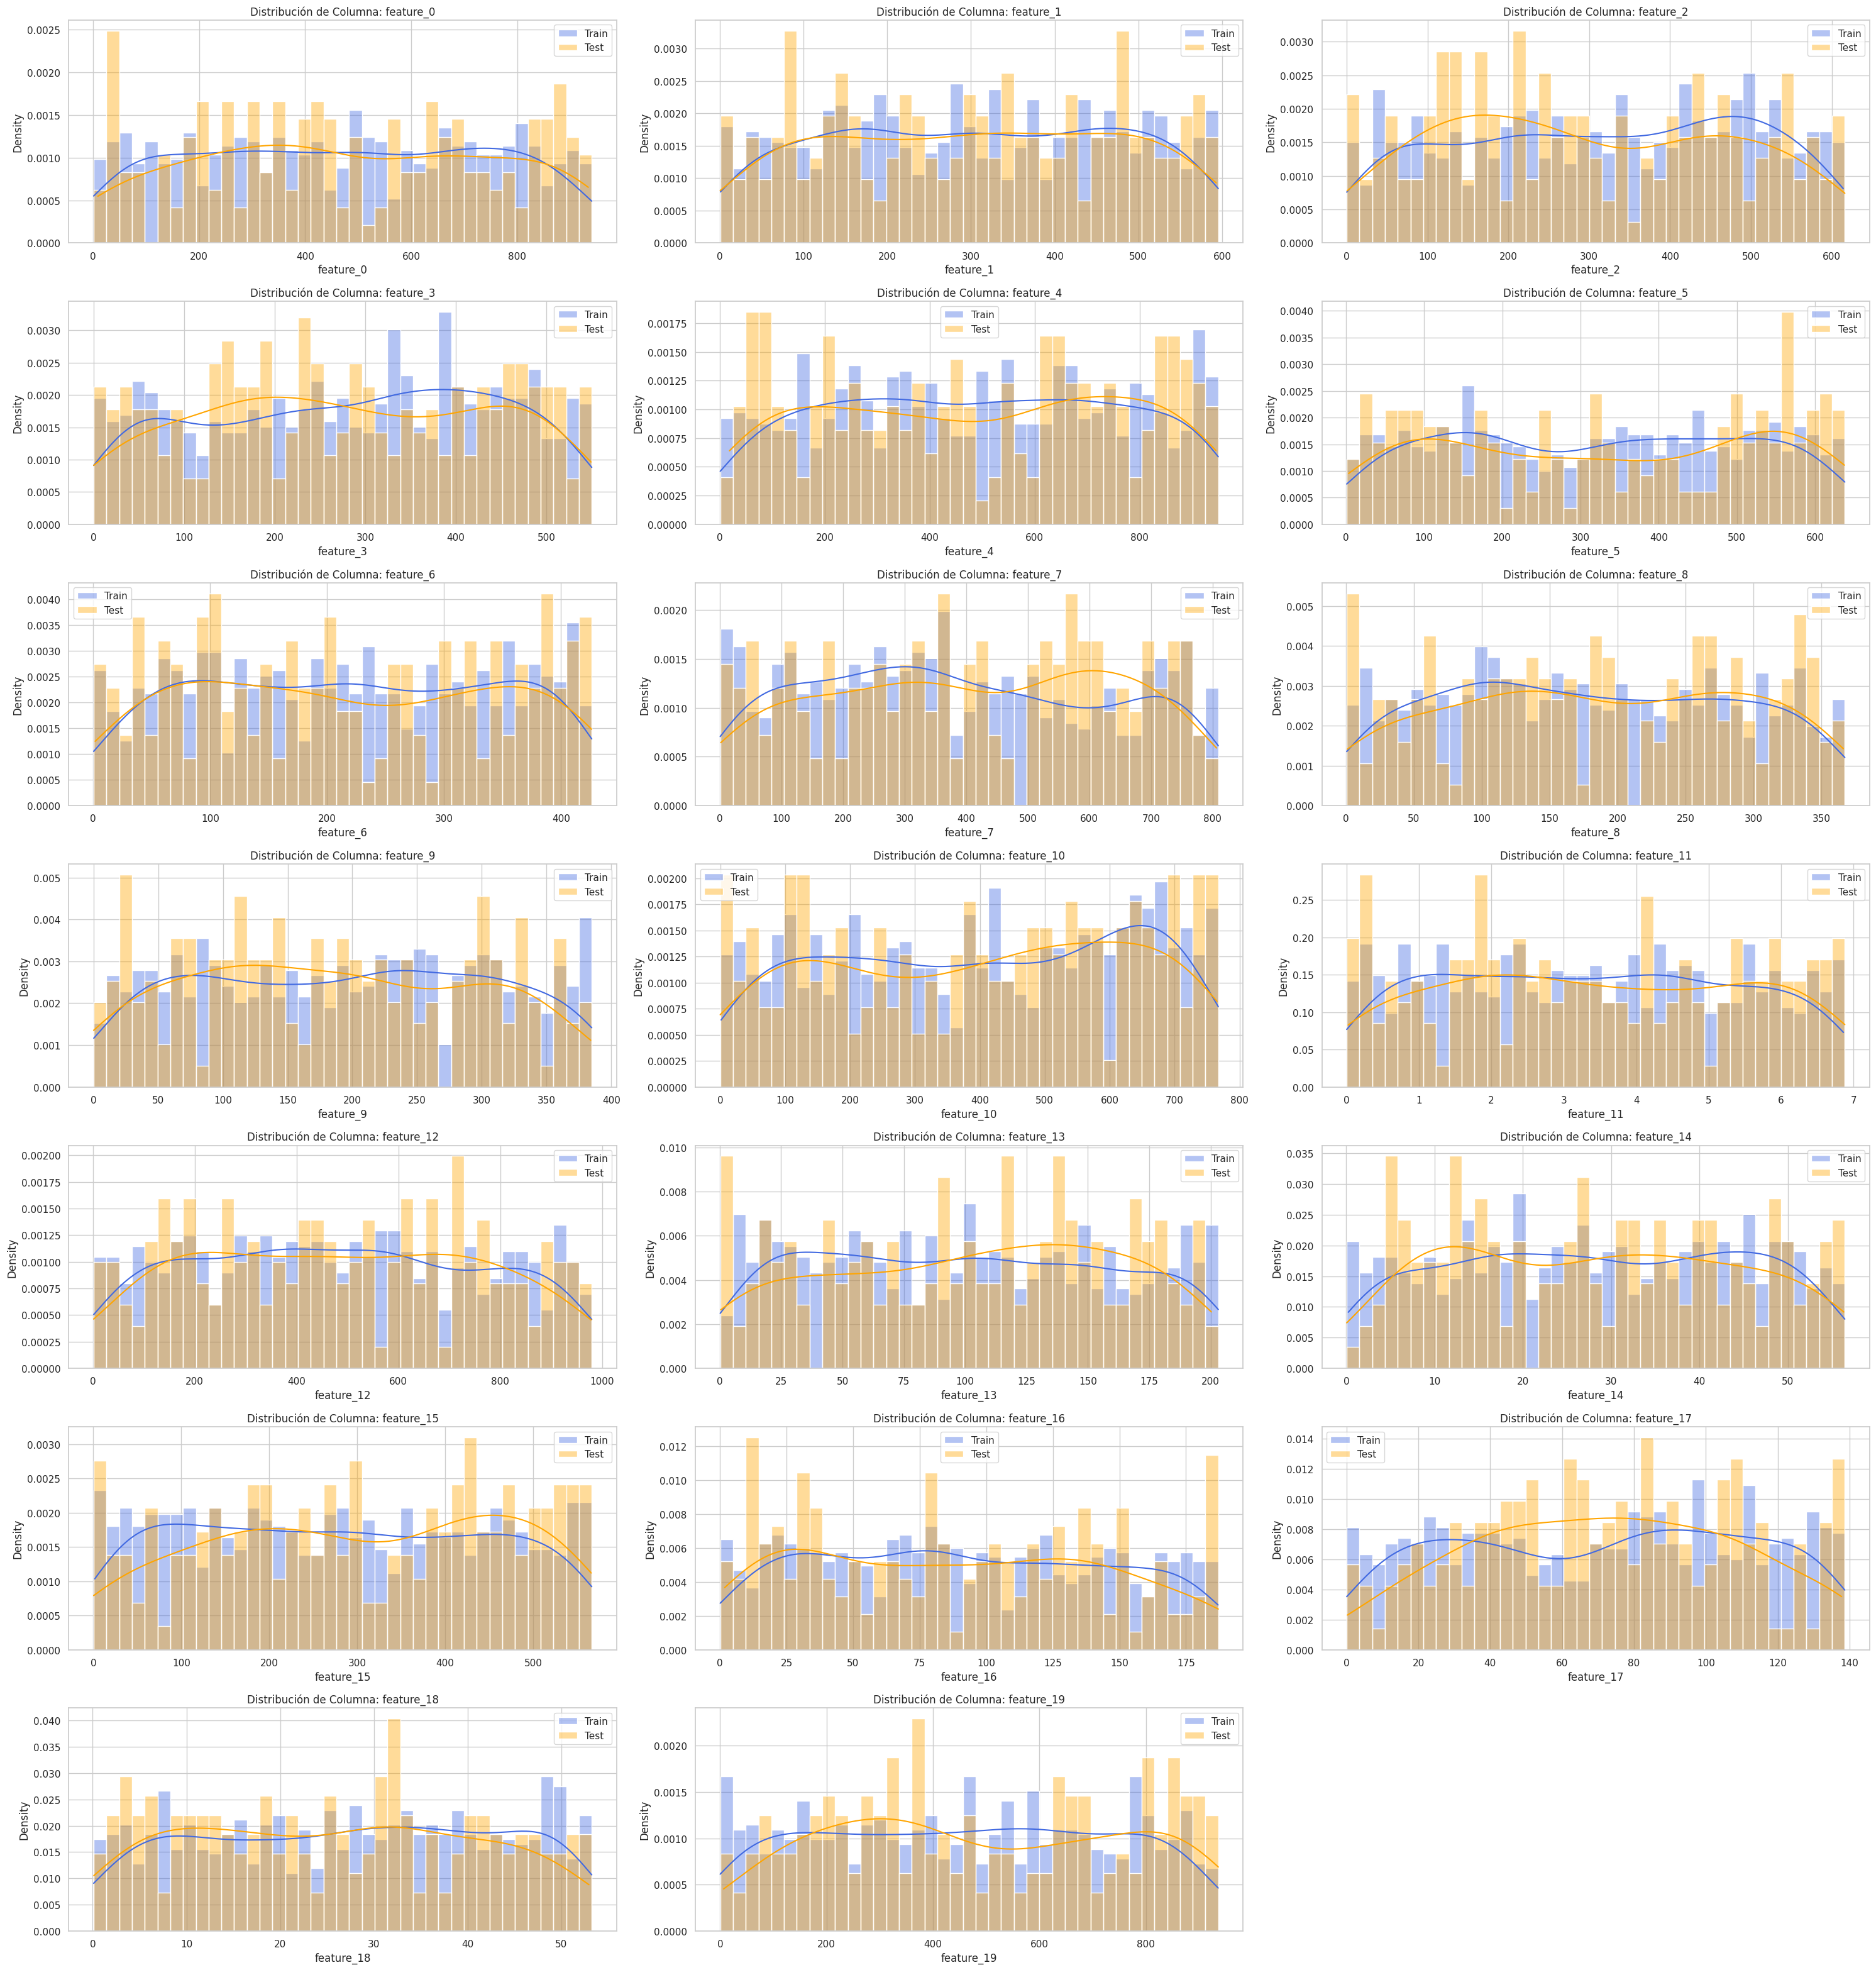

In [4]:
# Numeric columns bertween train and test
numeric_columns = df_test.select_dtypes(include=['int64', 'float64']).columns

# Plot distributions
n_cols = 3
n_rows = (len(numeric_columns) + n_cols - 1) // n_cols

# Aspects of each subplot
fig, axes = plt.subplots(n_rows, n_cols, figsize=(30, 4.5 * n_rows))
axes = axes.flatten() # Flatten axes to iterate

for i, col in enumerate(numeric_columns):
  # Calculate shared bin
  min_val = min(df_train[col].min(), df_test[col].min())
  max_val = max(df_train[col].max(), df_test[col].max())
  shared_bins = np.linspace(min_val, max_val, 40)  # 26 edges = 25 equal-width bins

  # Histograms
  sns.histplot(df_train[col], bins=shared_bins, color="royalblue", label="Train", kde=True, stat="density", alpha=0.4, ax=axes[i]) # Histogram train - stat:count
  sns.histplot(df_test[col], bins=shared_bins, color="orange", label="Test", kde=True, stat="density", alpha=0.4, ax=axes[i]) # Histogram test - stat:count
  axes[i].set_title(f"Distribución de Columna: {col}")
  axes[i].legend()

# Hide empty charts
for j in range(i + 1, len(axes)):
  fig.delaxes(axes[j])

# Show chart
plt.tight_layout()
plt.show()

### Detección de valores atípicos

Me muestra qué variables numéricas tienen valores extremos que podrían afectar el entrrenamiento del modelo

**Conclusion:** Al observar las graficas se concluye que:

- Existen **0 valores atípicos extremos** en Train. Ninguna de las variables tiene valores anómalos que puedan sesgar el modelo. POr lo que no se necesita eliminar filas ni aplicar técnicas de recorte

- Existe una **simetría total** en todas las variables ya que la mediana parte cada boxploit por la mitad y cada uno de los extremos tienen prácticamente el mismo largo, confirmando nuevamente que los datos están repartidos de forma uniforme y equilibrada

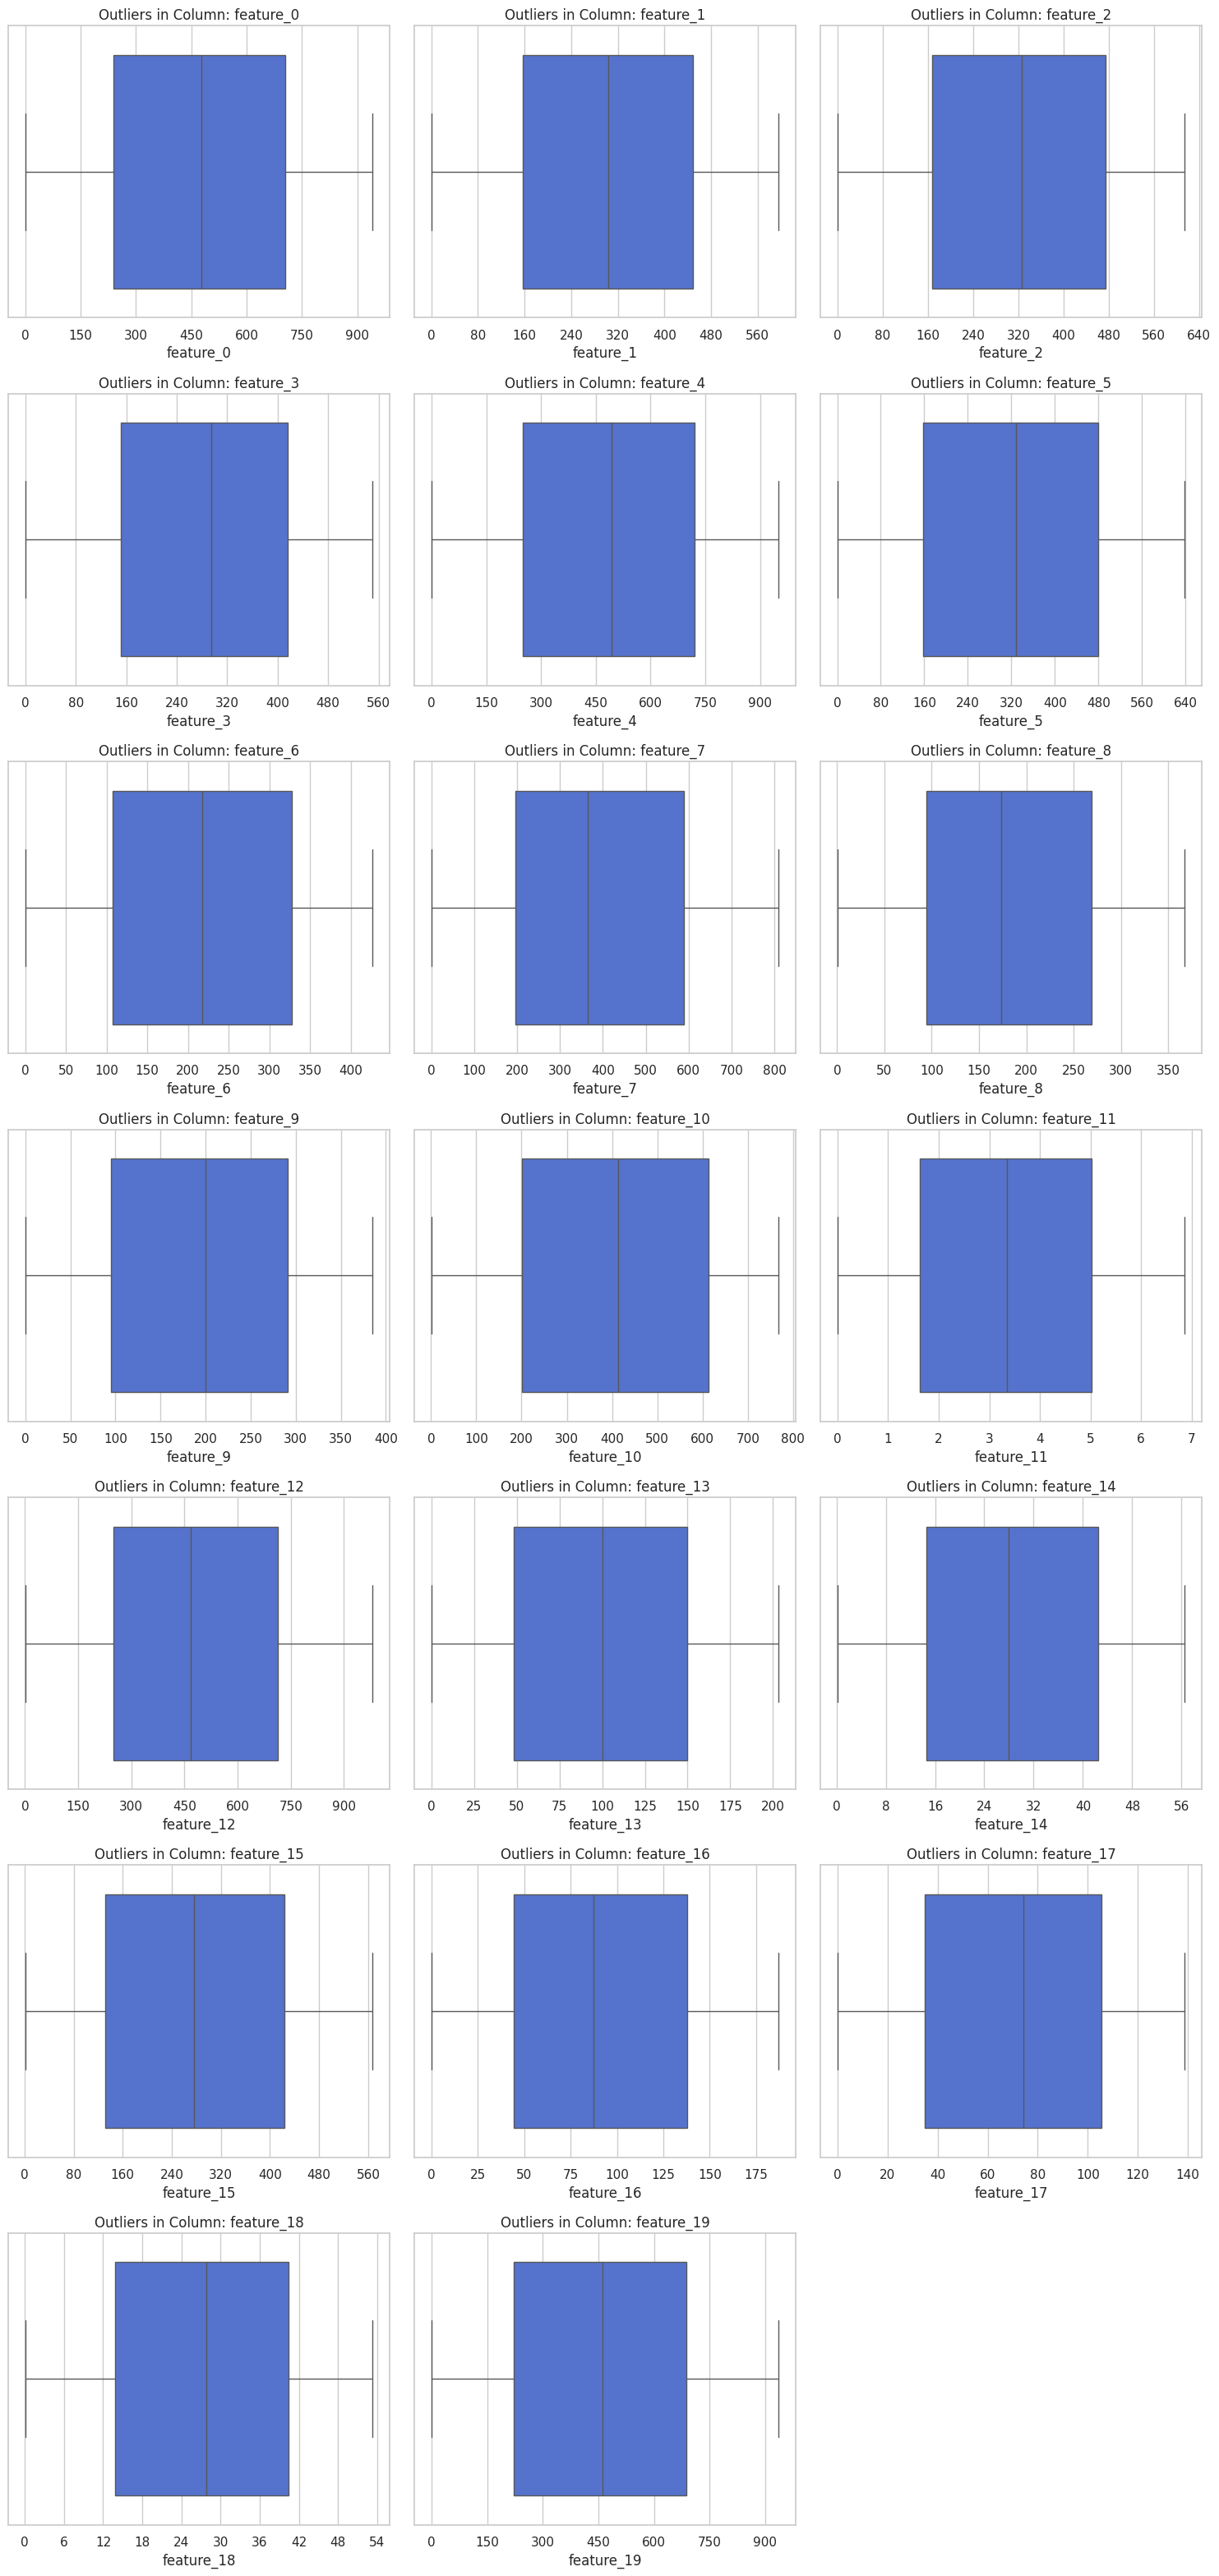

In [5]:
# Aspects of each subplot
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4.5 * n_rows))
axes = axes.flatten() # Flatten axes to iterate

for i, col in enumerate(numeric_columns):
  sns.boxplot(x=df_train[col], color="royalblue",ax=axes[i])
  axes[i].set_title(f"Outliers in Column: {col}")

  # Increase the number of ticks on X-axis
  axes[i].xaxis.set_major_locator(plt.MaxNLocator(integer=True )) #integer=True or 15

# Hide empty charts
for j in range(i + 1, len(axes)):
  fig.delaxes(axes[j])

# Show chart
plt.tight_layout()
plt.show()

### Variables Categóricas

Me muestra qué variables pueden ser categóricas (incluyendo aquellas numéricas que podrían ser numéricas)

**Conclusion:** Al observar las graficas se concluye que:

- Existen **0 variables categóricas** y que absolutamente todas las variables tienen mínimo 800 valores diferentes en Train. Se realizó esta prueba ya que la variable *feature_11*, al tener valores entre 0 y 7, se pensó en un primer momento como variable categórica pero quedó descartado


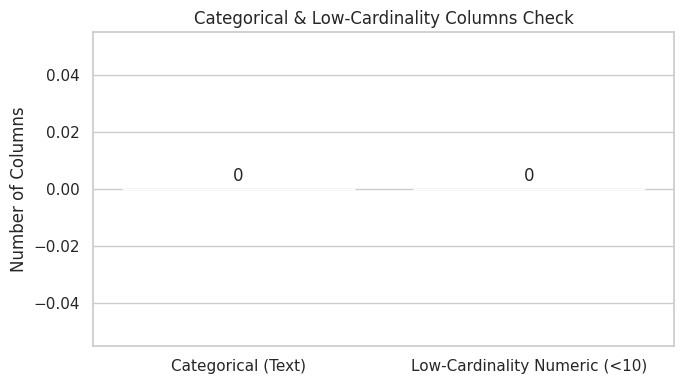

In [6]:
# Unique values from column that consider categorical
unique_values = 10

# Categorical variables
categorical_cols = df_train.select_dtypes(include=['object', 'category', 'string']).columns
low_cardinality_cols = [col for col in df_train.select_dtypes(include=['number']).columns if df_train[col].nunique() < unique_values]  # Numeric columns with < 10 unique values

# Summary dictionary with only those two groups
summary_counts = {
    'Categorical (Text)': len(categorical_cols),
    f'Low-Cardinality Numeric (<{unique_values})': len(low_cardinality_cols)
}

# Plot Bar Chart
plt.figure(figsize=(7, 4))
ax = sns.barplot(x=list(summary_counts.keys()), y=list(summary_counts.values()), hue=list(summary_counts.keys()), palette="viridis", legend=False)
plt.title("Categorical & Low-Cardinality Columns Check")
plt.ylabel("Number of Columns")

# Add exact count labels on top of each bar
for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.tight_layout()
plt.show()


### Matriz de correlación y ranking de importantcia con la variable objetivo

 Existen 21 columnas por lo ques es difícil ver por completo la matriz de correlación. POr lo anterior, la idea es dibujar el mapa de calor completo a la izquierda y un gráfico de barras ordenado a la derecha que muestra que variables se correlacionan más con la variable objetivo

 **Conclusion:** Al observar las graficas se concluye que:

- Existen **4 variables que dominan la relación lineal**. Estas destacan por encima con correlaciones positivas moderadas:
    - **feature_2:** Con **0.55** es la variable más predictora de todo el conjunto

- El resto de las 16 variables tienen una **correlación lineal casi NULA** con target entre -0.06 y +0.06. Lo que significa que aportan muy poca señal directa pero pueden tener otros tipos de correlaciones

- No se necesita eliminar columnas antes de entrenar ya que no existe multicolinealidad. Lo que significa que las variables son independientes entre si y no hay **información duplicada ni redundante**

- Las 4 variables con mayor correlación tienen una correlación positiva, lo que indica que, **a medida que aumentan los valores de estas variables, el valor de la variable objetivo también tiene a subir**



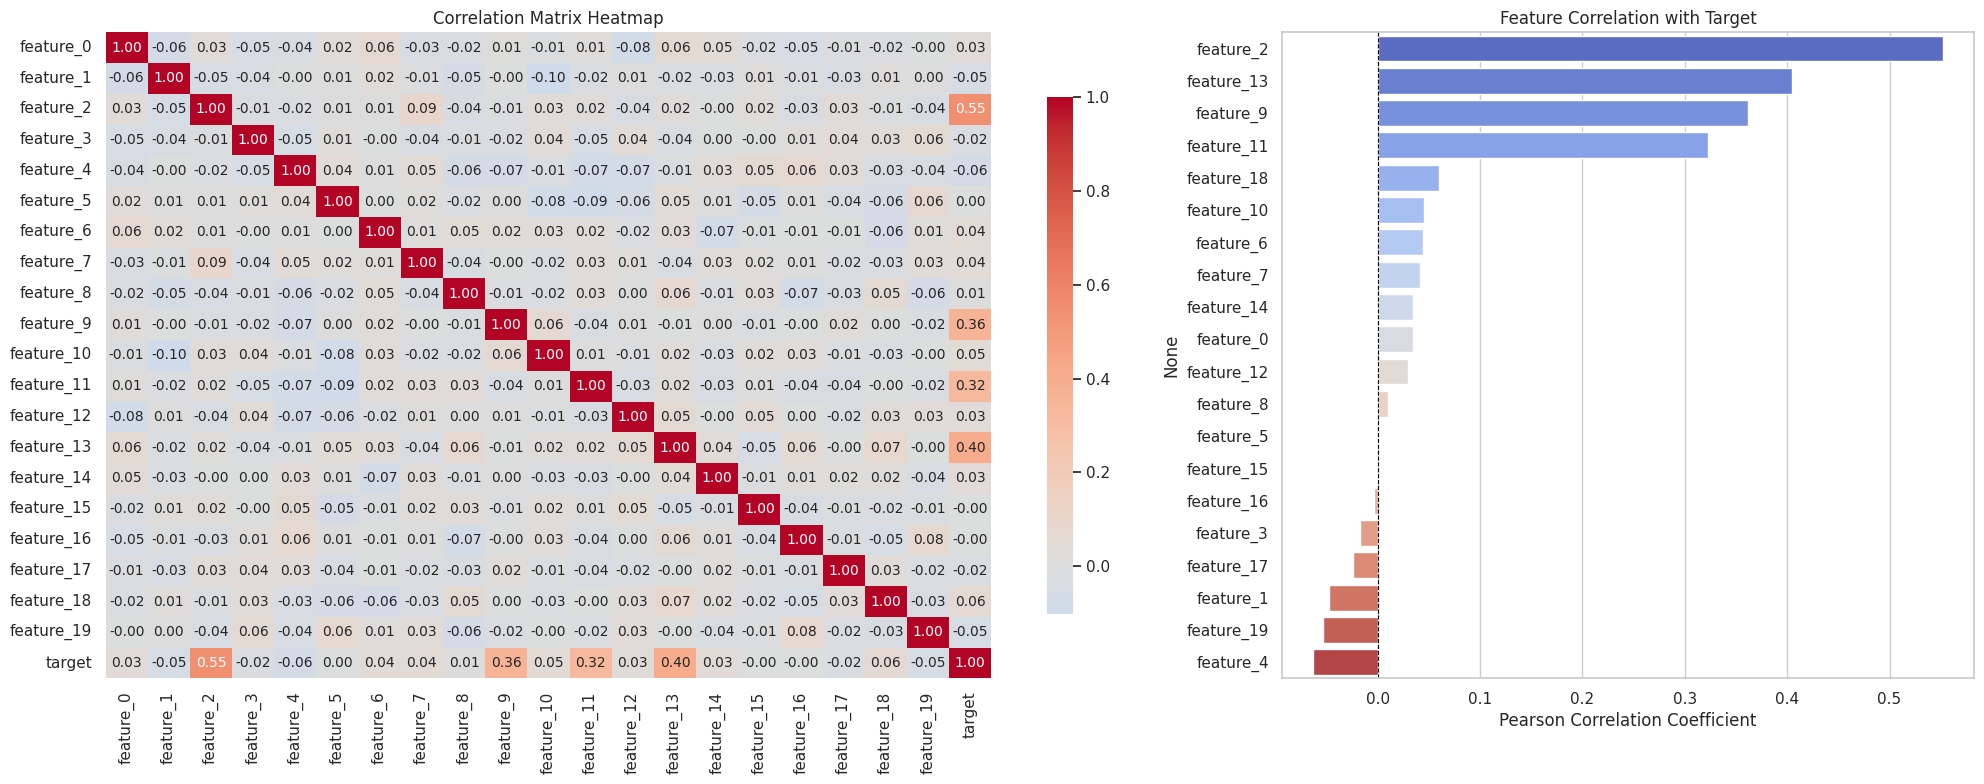

In [7]:
# Calculate correlation matrix
corr_matrix = df_train.corr()

fig, axes = plt.subplots(1, 2, figsize=(20, 8), gridspec_kw={"width_ratios": [1.6, 1]})

# Subplot 1: Correlation Heatmap
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, cbar_kws={"shrink": 0.8}, annot_kws={"size": 10}, ax=axes[0])
axes[0].set_title("Correlation Matrix Heatmap")

# Subplot 2: Bar Chart of correlations in target variable
target_corr = corr_matrix["target"].drop("target").sort_values(ascending=False)
sns.barplot(x=target_corr.values, y=target_corr.index, hue=target_corr.index, palette="coolwarm", legend=False, ax=axes[1])

# Tittles
axes[1].set_title("Feature Correlation with Target")
axes[1].set_xlabel("Pearson Correlation Coefficient")
axes[1].axvline(x=0, color="black", linewidth=0.8, linestyle="--")

# Show chart
plt.tight_layout()
plt.show()


## Automatic Report

### Generación del Reporte

El objetivo es generar un reporte en formato HTML utilizando la librería **Pandas Profiling**

In [8]:
# Metadata's configuration
metadata = {
  "description": "Exploratory Data Analysis.",
  "creator": "Tomas Jimenez",
  "copyright_year": 2026
}

# Correlation's configuration
corr_config = {
    "auto": {"calculate": True},
    "pearson": {"calculate": True},
    "spearman": {"calculate": True},
    "kendall": {"calculate": True},
    "phi_k": {"calculate": True},
    "cramers": {"calculate": True},
}

# Interactions' config
interactions_config = {
    "continuous": True,
    "targets": ["target"]
}

# Generate exploratory report for train and test
train_report = ProfileReport(
    df_train,
    title="Train Report",
    explorative=True,
    dataset=metadata,
    correlations=corr_config,
    interactions=interactions_config
)

test_report = ProfileReport(
    df_test,
    title="Test Report",
    explorative=True,
    dataset=metadata,
    correlations=corr_config,
    interactions={"continuous": False}  # Avoid generating heavy plots for test
)

# Combine reports side by side comparision
comparision_report = train_report.compare(test_report)

# Save and Download
comparision_report.to_file("Exploratory_Data_Analysis_Report.html")
files.download("Exploratory_Data_Analysis_Report.html")


/usr/local/lib/python3.13/dist-packages/ydata_profiling/compare_reports.py:191: UserWarning: The datasets being profiled have a different set of columns. Only the left side profile will be calculated.
  warnings.warn(


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 21/21 [00:00<00:00, 75.38it/s]


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 20/20 [00:00<00:00, 100.54it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Interpretación del Reporte

#### 1. Confirmación de la variable líder

En el reporte, el sistema de laertas automáticas que saca el reporte confirma exactamente que la variable *feature_2* es la variable con mayor relación, inclusive analizando otros tipos de correlaciones

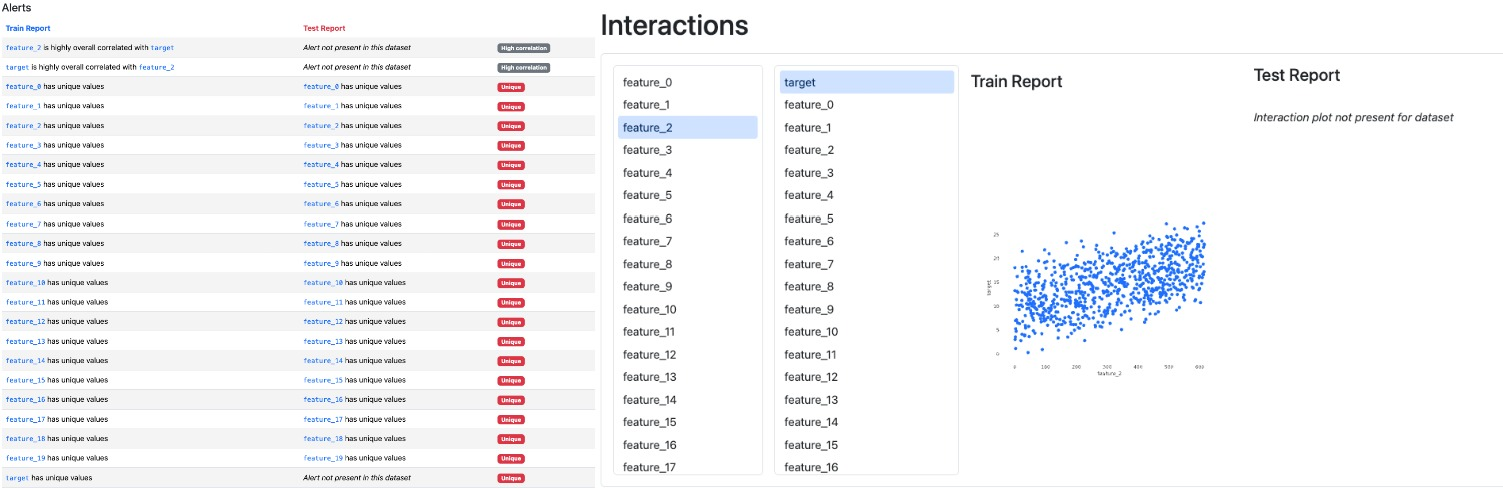

#### 2. Calidad e Integridad de los datos

En el reporte se logró visualizar que no es necesario nada de limpieza, no hay filas duplicadas, no hay valores infinitos, todos los datos son homogéneos (float64) y cada una de las muestras es totalmente diferente

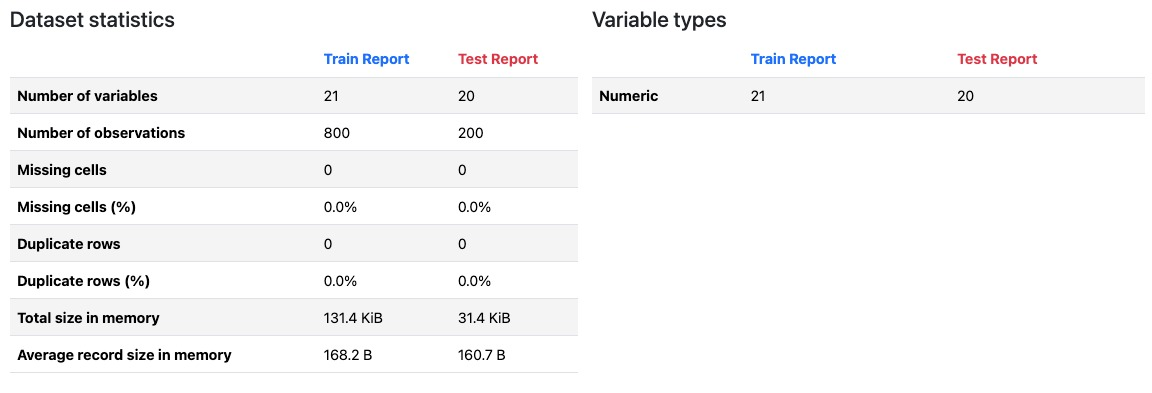

#### 3. Consistencia entre Train y Test

Para asegurar el correcto entrenamiento del modelo con el dataset de Train y que logre predecir correctamente en el dataset de Test (que no tiene la variable objetivo) se compararon y analizaron los datasets, analizando histogramas, medias, medianas y desviaciones estándar en donde son prácticamente idénticas en todas las columnas. Por lo anterior, asegura que el modelo entrenado sobre el dataset de Train con una división de 80/20 se comportará de forma estable al predecir sobre las 200 muestras del dataset de Train

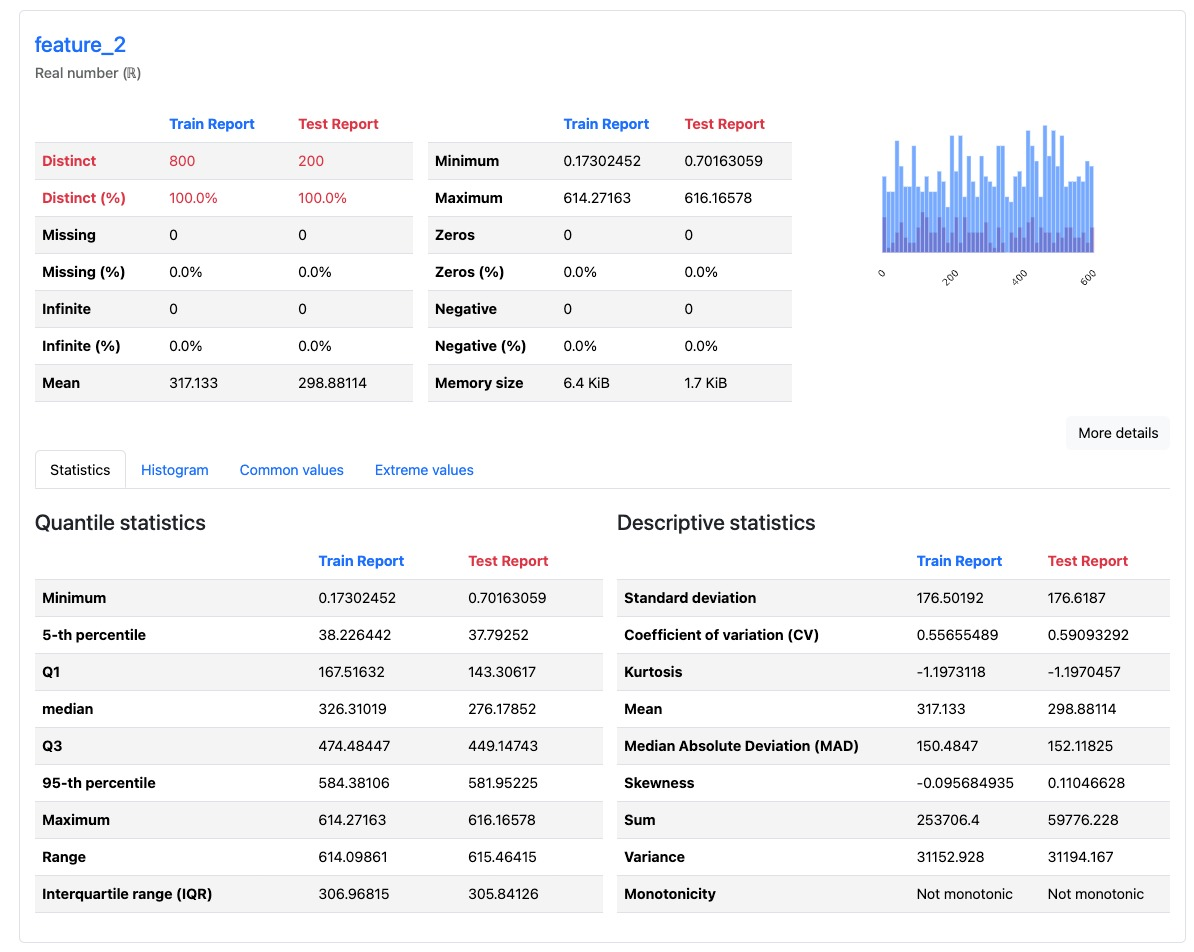

#### 4. Comportamiento de las Variables Predictoras

- El dataset presenta distrinuciones uniformes y limpias en todas las características con histogramas planos, skewness cercana a 0 y curtosis alrededor de -1.20 (que es propia de distribuciones uniformes). En conjunto con los boxplots nos asegura que no existen valores atípicos (outliers)

  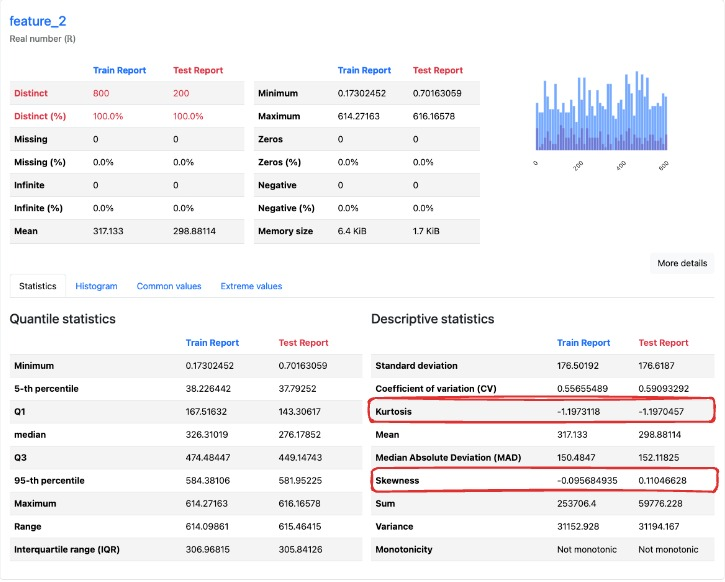

- Las variables manejan rangos muy distintos. Por ejemplo *feature_11* va de 0 a 7, mientras que *feature_0* y *feature_12* llegan casi a 1000. POr lo anterior, **será muy crítico que apliquemos escalado de características (StandardScaler o MinMaxScaler) si se llegan a utilizar modelos sensibles a la escala (Regresión Lineal, SVR, KNN o Redes neuronales)**

  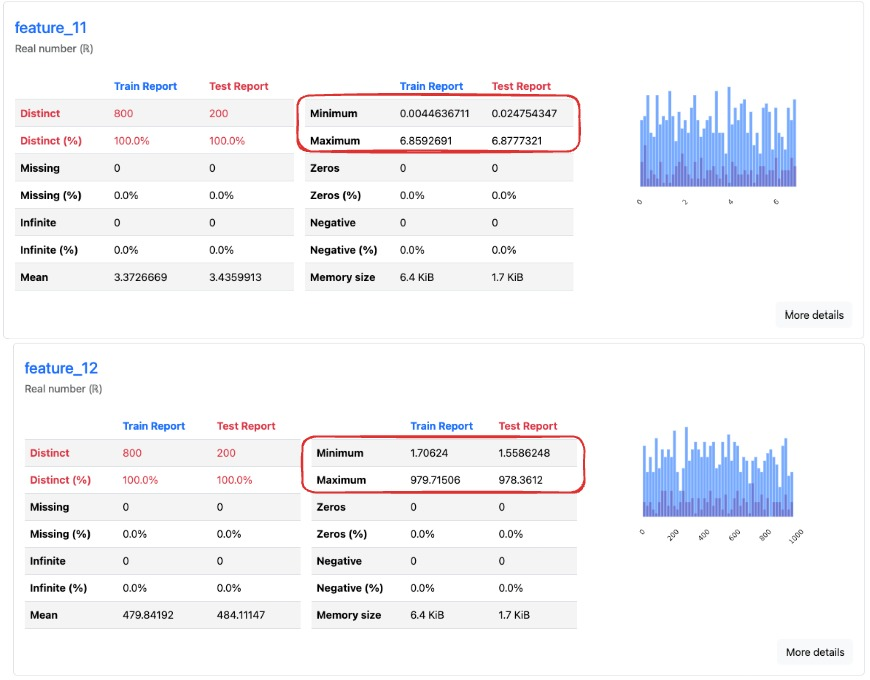

#### 5. Variable Objetivo (target)

Se descubrió que la variable objetivo es una variable continua simétrica con un **rango desde 0.28 a 27.36**, una **media de 14.63**, una **mediana de 14.69**. Así se concluye que el problema se trata de una **Regresión** sin necesidad de transformar el objetivo.

Se plantea una hipótesis de usar modelos no lineales basados en árboles (random Forest, Gradient Boosting) ya que existen 16 variables que no tienen correlación lineal (valor cercano a 0).

# Data Preparation

En esta etapa preparamos los datos para el entrenamiento de los algoritmos de Machine Learning. Con base en las conclusiones del Análisis Exploratorio de Datos (EDA) no es necesario aplicar procesos de limpieza ni codificación

Por lo tanto, esta se enfoca exlusivamente en dos pasos fundamentales:

- **Data Splitting:** Debemos de dividir nuestro de dataset de Train para Train 80% y Test 20% ya que el dataset de Test no contiene la variable objetivo y se considerarán como muestras nuevas

- **Feature Scaling:** Vamos a estandarizar de las 20 variables predictoras para evitar fugas de datos o data leakage y así garantizamos que las diferencias de escala no sesguen a los modelos lineales o basados en distancias

## Data Splitting

Nuestro Dataset cuenta con 20 características predictoras *(x)* y la variable objetivo *(target)*. La idea es separar de las 20 características predictoras la variable objetivo para luego dividir el dataset de Train en un 80% para entrenamiento interno (640 filas) y un 20% para validación (160 filas). Con esto logramos mantener el dataset de Test (200 filas) completamente aislado para la inferencia

In [9]:
# Separate predictives features and target variables
X = df_train.drop(columns=["target"])
y = df_train["target"]

# Split Train dataset into 80% to train and 20% to test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Verify and print results
print("Data Splitting completed:")
print(f"- Data Train:   X_train {X_train.shape},  y_train {y_train.shape}")
print(f"- Data Test:    X_test {X_test.shape},   y_test {y_test.shape}")
print(f"- Final Unseen Test:    df_test={df_test.shape}")

Data Splitting completed:
- Data Train:   X_train (640, 20),  y_train (640,)
- Data Test:    X_test (160, 20),   y_test (160,)
- Final Unseen Test:    df_test=(200, 20)


##  Feature Scaling

### Process

In [10]:
# Intialize the StandardScaler
scaler = StandardScaler()

# Fit and transform X_train
X_train_scaled = scaler.fit_transform(X_train)

# Fit and transform to internal test and final unseen test sets
X_test_scaled = scaler.transform(X_test)
df_test_scaled = scaler.transform(df_test)

# Verify and print results
print("Feature Scaling completed successfully:")
print(f"- X_train_scaled shape: {X_train_scaled.shape} | Mean: {X_train_scaled.mean():.2f}, Std: {X_train_scaled.std():.2f}")
print(f"- X_test_scaled shape:  {X_test_scaled.shape} | Mean: {X_test_scaled.mean():.2f}, Std: {X_test_scaled.std():.2f}")
print(f"- df_test_scaled shape: {df_test_scaled.shape} (Final unseen samples)")

Feature Scaling completed successfully:
- X_train_scaled shape: (640, 20) | Mean: -0.00, Std: 1.00
- X_test_scaled shape:  (160, 20) | Mean: 0.01, Std: 1.00
- df_test_scaled shape: (200, 20) (Final unseen samples)


### Visualization

 **Conclusion:** Al observar las graficas se concluye que:

- Antes del escalado se observa una desproporción extrema de magnitudes. Mientras *feature_11* forma una aguja estrecha y altísima pegada al 0 ya que sus valores van de 0 a 7; mientras que por otro lado, *feature_0*, *feature_2*, *feature_9* y *feature_13* quedan completamente en la base extendiéndose hasta 1000. Por lo anterior, se concluye que sin escalar, cualquier modelo lineal o basado en distancias ignoraría por completo *feature_11* **texto en negrita**

- Una vez hecho el escalado todas las variables quedaron **alineadas exactamente bajo la misma escala**, centradas en 0 , moviendose de forma simeetrica entre -2 y +2 sin llegar a afectar los datos

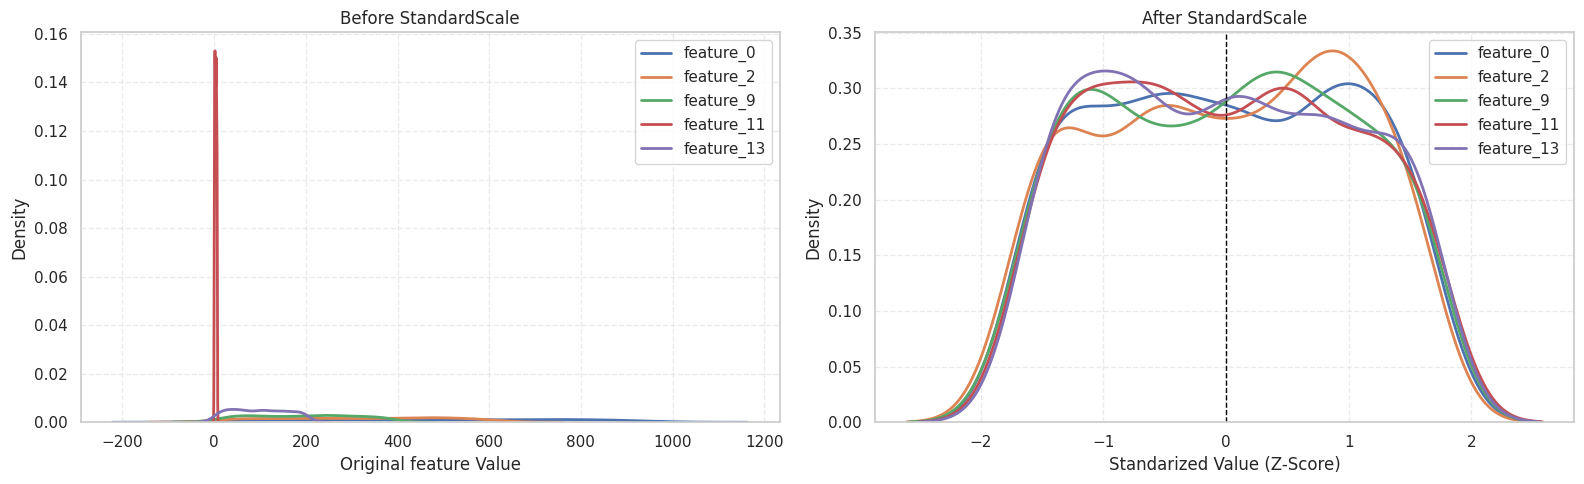

In [11]:
# Convert to a DataFrame
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X_train.columns)

# Futures with different ranges
sample_cols = ["feature_0", "feature_2", "feature_9", "feature_11", "feature_13"]

# Aspects of each subplot
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Subplot 1: Before Scaling
for col in sample_cols:
  sns.kdeplot(X_train[col], label=col, ax=axes[0], linewidth=2)

# Configurations Subplot 1
axes[0].set_title("Before StandardScale")
axes[0].set_xlabel("Original feature Value")
axes[0].set_ylabel("Density")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.4)

# Subplot 2: After Scaling
for col in sample_cols:
  sns.kdeplot(X_train_scaled_df[col], label=col, ax=axes[1], linewidth=2)

# Configurations Subplot 2
axes[1].set_title("After StandardScale")
axes[1].set_xlabel("Standarized Value (Z-Score)")
axes[1].set_ylabel("Density")
axes[1].legend()
axes[1].axvline(0, color="black", linestyle="--", linewidth=1, label="Mean")
axes[1].grid(True, linestyle="--", alpha=0.4)

# Display chart
plt.tight_layout()
plt.show()

# Modeling

Para esta fase se eligieron **Linear Regresion, Ridge, RandomForest, Gradient Boosting y XGBoost** ya que representan las dos familias de algoritmos **más efectivos para datos tabulares**. Con este orden se logra:

1. Probar una hipótesis simple y ya luego capturar patrones complejos con apenas 800 filas. Ya que se iniciar con modelos que buscan líneas rectas (Linear y Ridge) debido a las 4 variables con correlación lineal y luego pasamos a modelos de árboles (Random Forest, Gradient Boosting, XGBoost) para descubrir si las otras 16 variables tienen relaciones curvas o interacciones ocultas

2. Estos modelos funcionan bien con datasets pequeños a diferencia de una Red Neuronal que necesita decenas de miles filas para no memorizar los datos (overfiting) debido a que tienen muchos parametros que pueden ajustar y hacer la gráfica de los datos tal cual

3. Los datos al **NO tener valores atípicos** y ser todos numéricos, los algoritmos propuestos operan en el escenario ideal

## Model definitions

In [12]:
# Baseline models dictionary
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "XGBoost": XGBRegressor(n_estimators=200, learning_rate=0.05, random_state=42)
}

## Model Training

In [13]:
# Trained models dictionary and their predictions
trained_models = {}
predictions = {}

# Train each model
for name, model in models.items():
  model.fit(X_train_scaled, y_train)

  # Genrate predictions in the internat test set
  y_pred = model.predict(X_test_scaled)

  # Store results
  trained_models[name] = model
  predictions[name] = y_pred
  print(f"Model Trained: {name}")

print("\n All models trained")

Model Trained: Linear Regression
Model Trained: Ridge Regression
Model Trained: Random Forest
Model Trained: Gradient Boosting
Model Trained: XGBoost

 All models trained


## Model Evaluation and Metrics

Tomaremos las predicciones guardadas y calcularemos las tres métricas pincipales de regresión: (RMSE, MAE y R2 Score) comparado contra los valores reales y ordenando la tabla final desde el menor error hasta el mayor.

In [14]:
# Calculate evaluation metrics for each model
metrics_list = []

for name, y_pred in predictions.items():
  rmse = root_mean_squared_error(y_test, y_pred)
  mae = mean_absolute_error(y_test, y_pred)
  r2 = r2_score(y_test, y_pred)

  metrics_list.append({
    "Model": name,
    "RMSE": rmse,
    "MAE": mae,
    "R2 Score": r2
  })

# Display the comparision sorted
result_df = pd.DataFrame(metrics_list).sort_values(by="RMSE").reset_index(drop=True)
display(result_df)

,Model,RMSE,MAE,R2 Score
0,Gradient Boosting,2.116202,1.721958,0.800532
1,XGBoost,2.129253,1.703849,0.798064
2,Random Forest,2.498592,1.999858,0.721933
3,Linear Regression,2.611788,2.108786,0.696167
4,Ridge Regression,2.612181,2.109524,0.696076


## Performance Visualization

### Actual vs Predicted Plot & Residual Plot

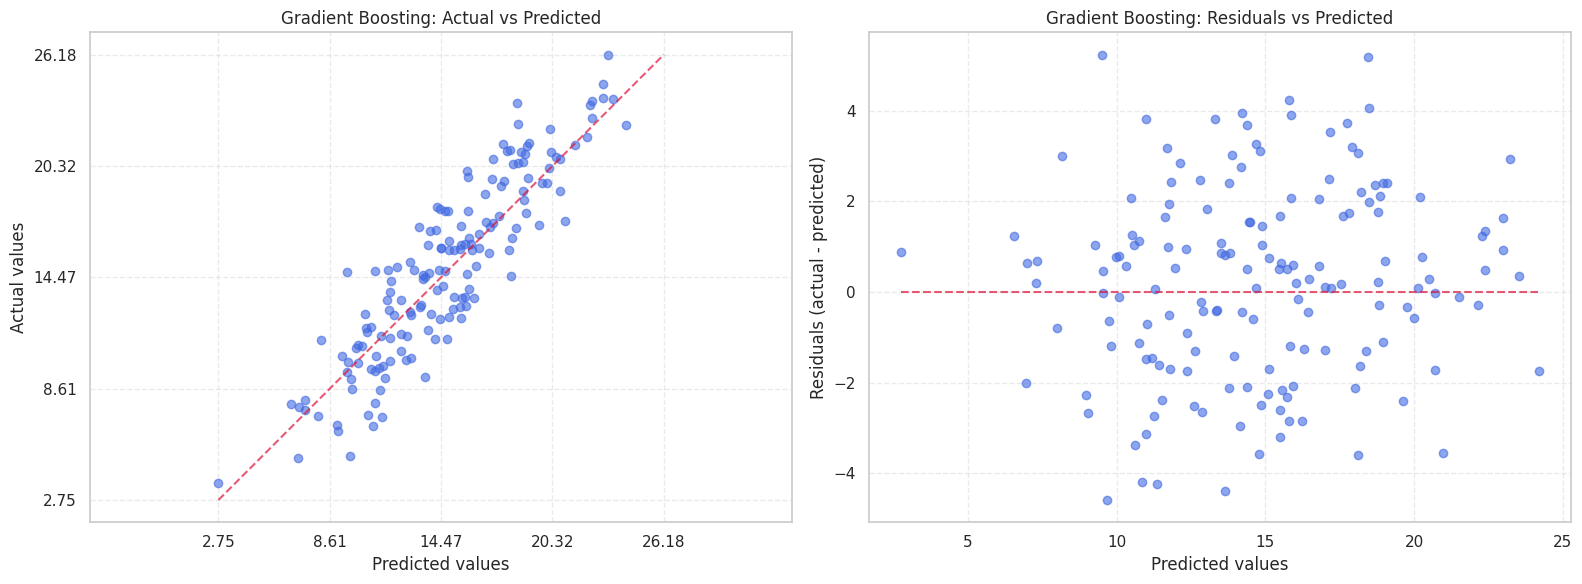

In [15]:
# Select the best model based on lowest RWSE
best_model_name = result_df.loc[0, "Model"]
best_y_pred = predictions[best_model_name]

# Aspects of each subplot
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Actual vs Predicted Values
PredictionErrorDisplay.from_predictions(
    y_true=y_test,
    y_pred=best_y_pred,
    kind="actual_vs_predicted",
    ax=axes[0],
    scatter_kwargs={"alpha": 0.6, "color": "royalblue"},
    line_kwargs={"color": "crimson", "linestyle": "--"}
)

# Configurations Subplot 1
axes[0].set_title(f"{best_model_name}: Actual vs Predicted")
axes[0].grid(True, linestyle="--", alpha=0.4)

# Subplot 2: Residuals vs Predicted values
PredictionErrorDisplay.from_predictions(
    y_true=y_test,
    y_pred=best_y_pred,
    kind="residual_vs_predicted",
    ax=axes[1],
    scatter_kwargs={"alpha": 0.6, "color": "royalblue"},
    line_kwargs={"color": "crimson", "linestyle": "--"}
)

# Configurations Subplot 2
axes[1].set_title(f"{best_model_name}: Residuals vs Predicted")
axes[1].grid(True, linestyle="--", alpha=0.4)

# Display chart
plt.tight_layout()
plt.show()

### Overfiting Check & Feature Importance

Vamos a comparar cuánto se equivoca el modelo en los datos de entrenamiento frente a los datos de testeo

--- DIAGNOSIS Gradient Boosting: TRAIN VS TEST ---
Train RMSE: 1.1421 | Train R2: 0.9511
Test RMSE:  2.1162 | Test R2:  0.8005


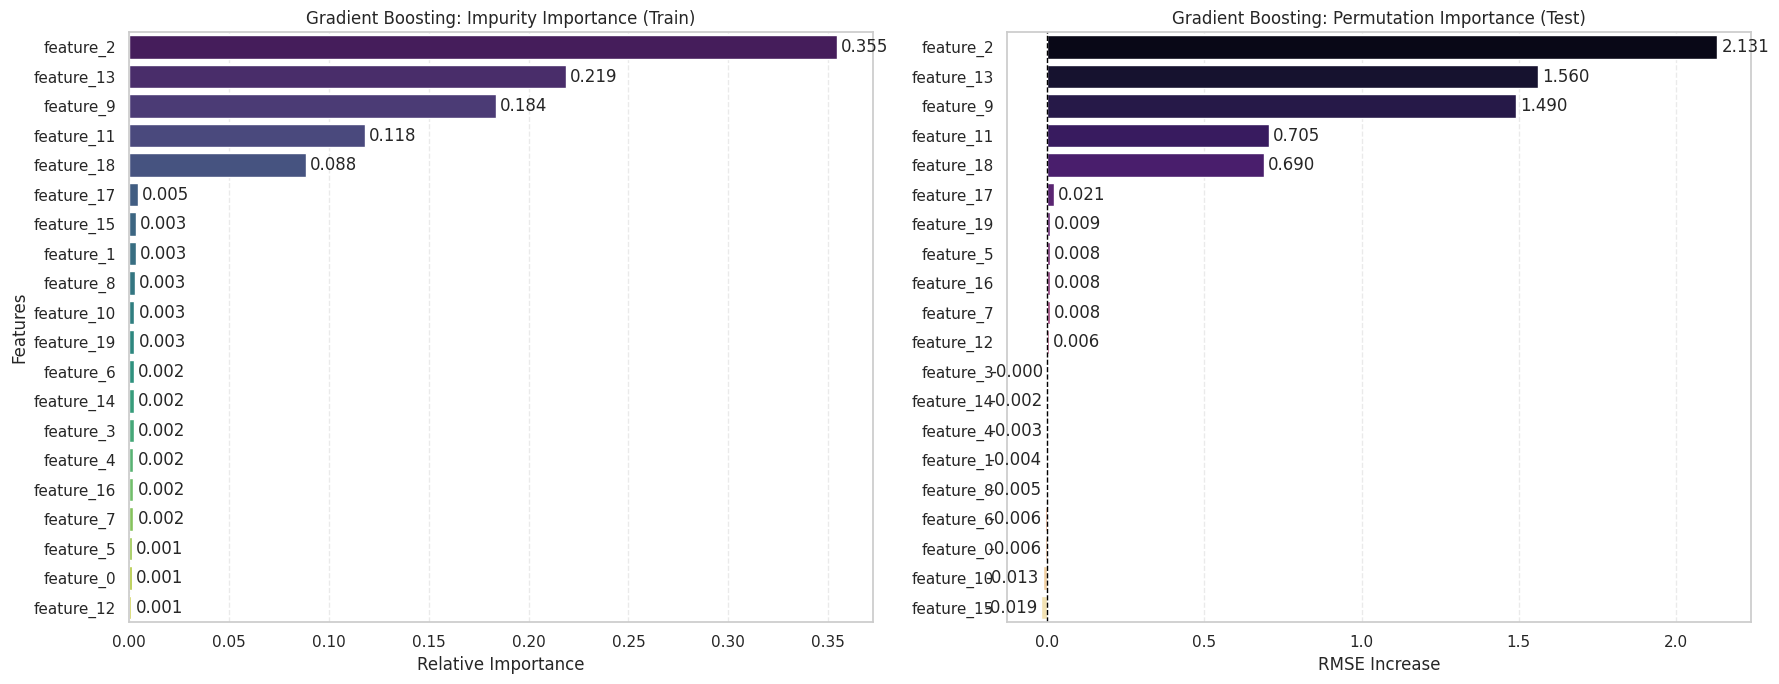

In [19]:
# Select the best model based on lowest RWSE
best_model_name = result_df.loc[0, "Model"]
best_model = trained_models[best_model_name]

# Check overfitting
train_preds = best_model.predict(X_train_scaled)
test_preds = best_model.predict(X_test_scaled)

# Show results
print(f"--- DIAGNOSIS {best_model_name}: TRAIN VS TEST ---")
print(f"Train RMSE: {root_mean_squared_error(y_train, train_preds):.4f} | Train R2: {r2_score(y_train, train_preds):.4f}")
print(f"Test RMSE:  {root_mean_squared_error(y_test, test_preds):.4f} | Test R2:  {r2_score(y_test, test_preds):.4f}")

# Calculate Permutation Importance on unseen test data
perm_result = permutation_importance(best_model, X_test_scaled, y_test, n_repeats=10, random_state=42, scoring="neg_root_mean_squared_error")
perm_imporances = pd.Series(perm_result.importances_mean, index=X_train.columns).sort_values(ascending=False)


# Extract and Plot Feature Importance
if hasattr(best_model, "feature_importances_"):
  importances = pd.Series(best_model.feature_importances_, index=X.columns).sort_values(ascending=False)

  # Set up figure side-by-side for comparision
  fig, axes = plt.subplots(1, 2, figsize=(18, 7))

  # Subplot 1: Impurity-Based Importance for Train
  sns.barplot(x=importances.values, y=importances.index, hue=importances.index, palette="viridis", legend=False, ax=axes[0])
  axes[0].set_title(f"{best_model_name}: Impurity Importance (Train)")
  axes[0].set_xlabel("Relative Importance")
  axes[0].set_ylabel("Features")
  axes[0].grid(axis="x", linestyle="--", alpha=0.4)

  # Write the number of each bin
  for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.3f", padding=3)

  # Subplot 2: Permutation Importance ofr Test Real Generalization
  sns.barplot(x=perm_imporances.values, y=perm_imporances.index, hue=perm_imporances.index, palette="magma", legend=False, ax=axes[1])
  axes[1].set_title(f"{best_model_name}: Permutation Importance (Test)")
  axes[1].set_xlabel("RMSE Increase")
  axes[1].set_ylabel("")
  axes[1].axvline(0, color="black", linestyle="--", linewidth=1)
  axes[1].grid(axis="x", linestyle="--", alpha=0.4)

  # Write the number of each bin
  for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.3f", padding=3)

# Display chart
plt.tight_layout()
plt.show()

## Analysis of Metrics

1. Los algoritmos de tipo Boosting fueron superiores a los modelos lineales. Siendo **Gradient Boosting** el que obtuvo el mejor desempeno y seguido muy de cerca con **XGBoost**, logrando explicar el 80% de la variabilidad de target

2. Con el entrenamiento se confirma las relaciones complejas. La **Regresion Lineal** y **Ridge** quedaron estancados en R2 (0.69 a comparacion de 0.80 y 0.79). Etsa brecha de mas de 10 puntos porcentuales demuestra que el problema **contiene patrone NO Lineales** e **interacciones entre variables que los modelos lineales no logran capturar**

3. El **plot de valor actual vs predecido** sigue una **estructura correcta de forma estrecha y uniforme alrededor de la diagonal e ideal a lo largo de todo el rango de valores.** Por otro lado, se evidencia que el modelo no tiene sesgos en los extremos por lo que el **modelo predice con igual solvencia tanto los valores bajos como los picos altos** sin quedarse corto ni aplanarse en la parte superior

4. Se tiene un comportamiento saludable de aleatoriedad pura (no existen patrones ocultos) en los residuos. Estos se distribuyen como una nube desordenada de arriba y abajo de la linea cero lo que indica que **Gradient Boosting** ya absorbio la estructura principal de los datos

5. Al hacer la ronda 1 del entrenamiento de los modelos parametros:

  ```
  # Baseline models dictionary
  models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "XGBoost": XGBRegressor(n_estimators=200, learning_rate=0.05,   random_state=42)
  }
  ```
  Se evidencia con el modelo de Gradient Boosting un **Overfiting moderado** ya que el modelo en el dataset de entrenamiento alcanza una precision casi perfecta (R2 = 0.95, RMSE = 1.14). Sin embargo al enfrentarse a datos nuevos el dataset de Test de nosotros su rendimiento cae (R2 = 0.80, RMSE=2.11). Esto se debe a que el modelo esta **memorizando pequenas variaciones aleatorias de las 15 variables que no aportan nada para encajar perfecto en las 630 filas de entrenamiento**

  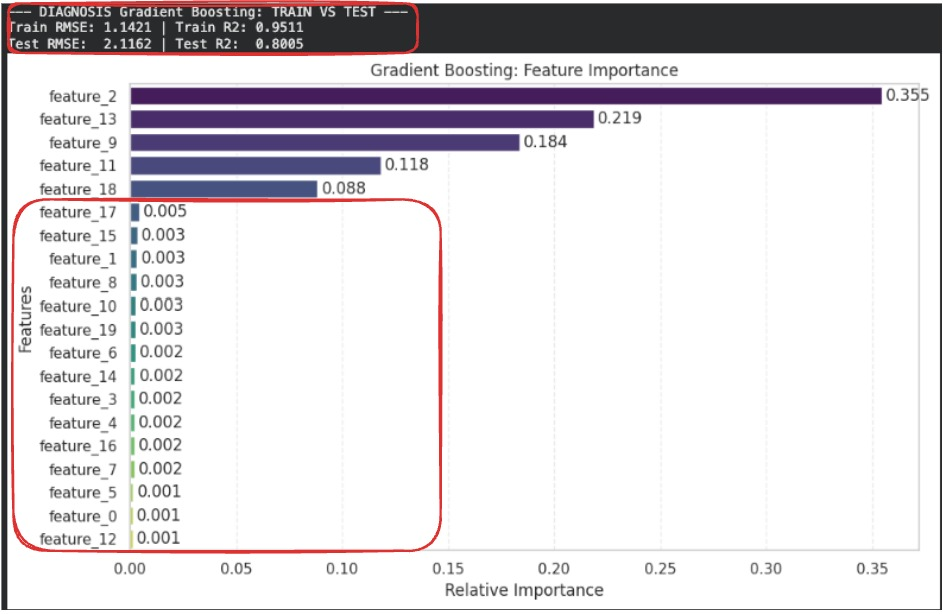

6. Solo hay 5 variables que hacen el 96.4% del trabajo de toda la capacidad predictiva del modelo. Lo nuevo es que la variable *feature_18* que en la Matriz de Correlacion marcaba 0.00 el **Gradient Boosting** le dio un **8.8%** de importancia. Lo anterior, demuestra que ***feature_18 tiene una relacion no lineal con la variable objetivo**.

7. Inclusive con Permutation Importance en el dataset de Test se evidencio que las 5 variables de importancia en el dataset de Train siguen siendo relevantes en el caso en que se llegue a inutilizar las 5 variables anteriores

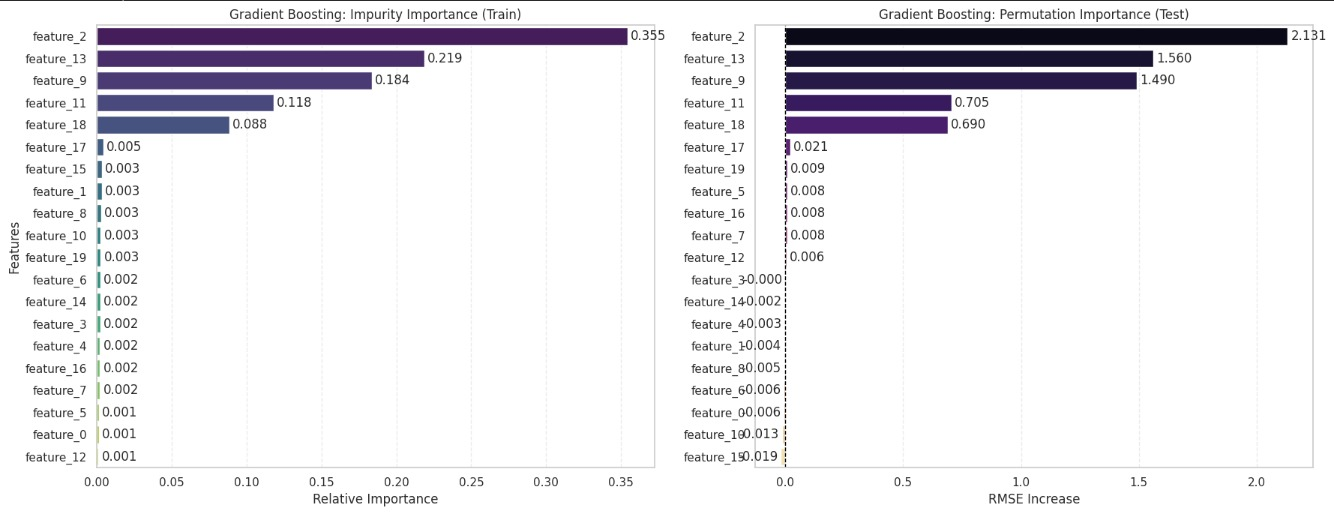




# Model Optimization

En esta fase buscamos optimizar el rendimiento del modelo ganador de la anterior fase **Gradient Boosting** y corregir el sobreajuste detectado en el diagnóstico anterior (Train R2 = 0.95 vs Test R2=0.80)

Con base en la evidencia obtenida, esta etapa se enfoca en dos pasos:

1. **Feature Selection:** Vamos a filtrar el conjunto de datos para conservar únicamente las 5 variables que aportaron el **96.4% de la capacidad predictiva**. De esta manera  eliminamos las 15 columnas restantes que actúan como ruido perjudicial y confunden al algoritmo

2. **Hyperparameter Tuning:** Utilizar **validación cruzada** sobre esas 5 variables limpias para encontrar la combinación óptima de profundidad, tasa de aprendizaje y número de árboles y así lograr un equilibrio entre sesgo y varianza que reduzca el error RMSE en datos nuevos.

## Feature Selection

Al observar los resultados concluimos que:

1. El RMSE bajó de 2.11 a 1.98, es decir, una **reducción del 6.3%** sin haber tocado todavía ningún hiperparámtro

2. El modelo pasó de explicar el 80.05% de la variabilidad de la variable objetivo a explicar el 82.51%. Un incremento de 2.46%

3. Al quitar las 15 columnas de ruido, el **R2 del dataset de Train bajó** de 0.95 a 0.94, mientras que **el R2 del dataset de Test subió**de 0.80 a 0.82. Por lo que es correcto afirmar que el **modelo dejó de memorizar coincidencias aleatorias en los datos de entrenamiento y concentró todos sus árboles en aprender las relaciones verdaderas de las 5 variables**

4. Se va a tener una **Eficiencia Computacional** por ya que el es **el 75% menos de los datos**, por lo que se acelera el entrenamiento, reduce el consumo de memoria y hace que el modelo sea mucho más fácil de intepretar y mantener

In [30]:
# Top 5 relevant features
top_5_features = ["feature_2", "feature_13", "feature_9", "feature_11", "feature_18"]

# Filter Train, Test and Final Unseen Test datasets
X_train_top5 = X_train[top_5_features]
X_test_top5 = X_test[top_5_features]
df_test_top5 = df_test[top_5_features]

# Train baseline Gradient Boosting only with the Top 5 features
gb_top5 = GradientBoostingRegressor(random_state=42)
gb_top5.fit(X_train_top5, y_train)

# Generate predictions for the Top 5 model
train_preds_top5 = gb_top5.predict(X_train_top5)
test_preds_top5 = gb_top5.predict(X_test_top5)

# Show diagnosis
print("--- FEATURE SELECTION RESULTS ---")
print(f"Train RMSE (20 features): {root_mean_squared_error(y_train, train_preds):.4f} | Train R2: {r2_score(y_train, train_preds):.4f}")
print(f"Test RMSE (20 features):  {root_mean_squared_error(y_test, test_preds):.4f} | Test R2:  {r2_score(y_test, test_preds):.4f}")
print(f"Train RMSE (5 features): {root_mean_squared_error(y_train, train_preds_top5):.4f} | Train R2: {r2_score(y_train, train_preds_top5):.4f}")
print(f"Test RMSE (5 features):  {root_mean_squared_error(y_test, test_preds_top5):.4f} | Test R2:  {r2_score(y_test, test_preds_top5):.4f}")

--- FEATURE SELECTION RESULTS ---
Train RMSE (20 features): 1.1421 | Train R2: 0.9511
Test RMSE (20 features):  2.1162 | Test R2:  0.8005
Train RMSE (5 features): 1.2366 | Train R2: 0.9427
Test RMSE (5 features):  1.9817 | Test R2:  0.8251


## Hyperparameter Tuning

In [28]:
# Hypeerparameter grid
param_grid = {
    "n_estimators":[100, 200, 300],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth":[2, 3, 4],
    "min_samples_leaf":[1, 5, 10],
    "subsample": [0.8, 1.0]
}

# Intialize GridSearch with 5 fold Cross-validation optimizing
grid_search = GridSearchCV(
    estimator=GradientBoostingRegressor(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    verbose=1
)

# Fit GreadSearchCV with the Top 5 features
grid_search.fit(X_train_top5, y_train)

# Get the best optimized model
best_gb_optimized = grid_search.best_estimator_

# Generate predictions
opt_train_preds = best_gb_optimized.predict(X_train_top5)
opt_test_preds = best_gb_optimized.predict(X_test_top5)

# Show diagnosis
print("\n--- HYPERPARAMETER TUNING RESULTS ---")
print(f"Best Parameters: {grid_search.best_params_}\n")
print(f"Default (5 features)   -> Train RMSE: {root_mean_squared_error(y_train, train_preds_top5):.4f} | Train R2: {r2_score(y_train, train_preds_top5):.4f} | Test RMSE: {root_mean_squared_error(y_test, test_preds_top5):.4f} | Test R2: {r2_score(y_test, test_preds_top5):.4f}")
print(f"Optimized (5 features) -> Train RMSE: {root_mean_squared_error(y_train, opt_train_preds):.4f} | Train R2: {r2_score(y_train, opt_train_preds):.4f} | Test RMSE: {root_mean_squared_error(y_test, opt_test_preds):.4f} | Test R2: {r2_score(y_test, opt_test_preds):.4f}")

Fitting 5 folds for each of 162 candidates, totalling 810 fits

--- HYPERPARAMETER TUNING RESULTS ---
Best Parameters: {'learning_rate': 0.1, 'max_depth': 2, 'min_samples_leaf': 10, 'n_estimators': 300, 'subsample': 0.8}

Default (5 features)   -> Train RMSE: 1.2366 | Train R2: 0.9427 | Test RMSE: 1.9817 | Test R2: 0.8251
Optimized (5 features) -> Train RMSE: 1.1525 | Train R2: 0.9502 | Test RMSE: 1.7638 | Test R2: 0.8614


## Performance Visualization Optimized

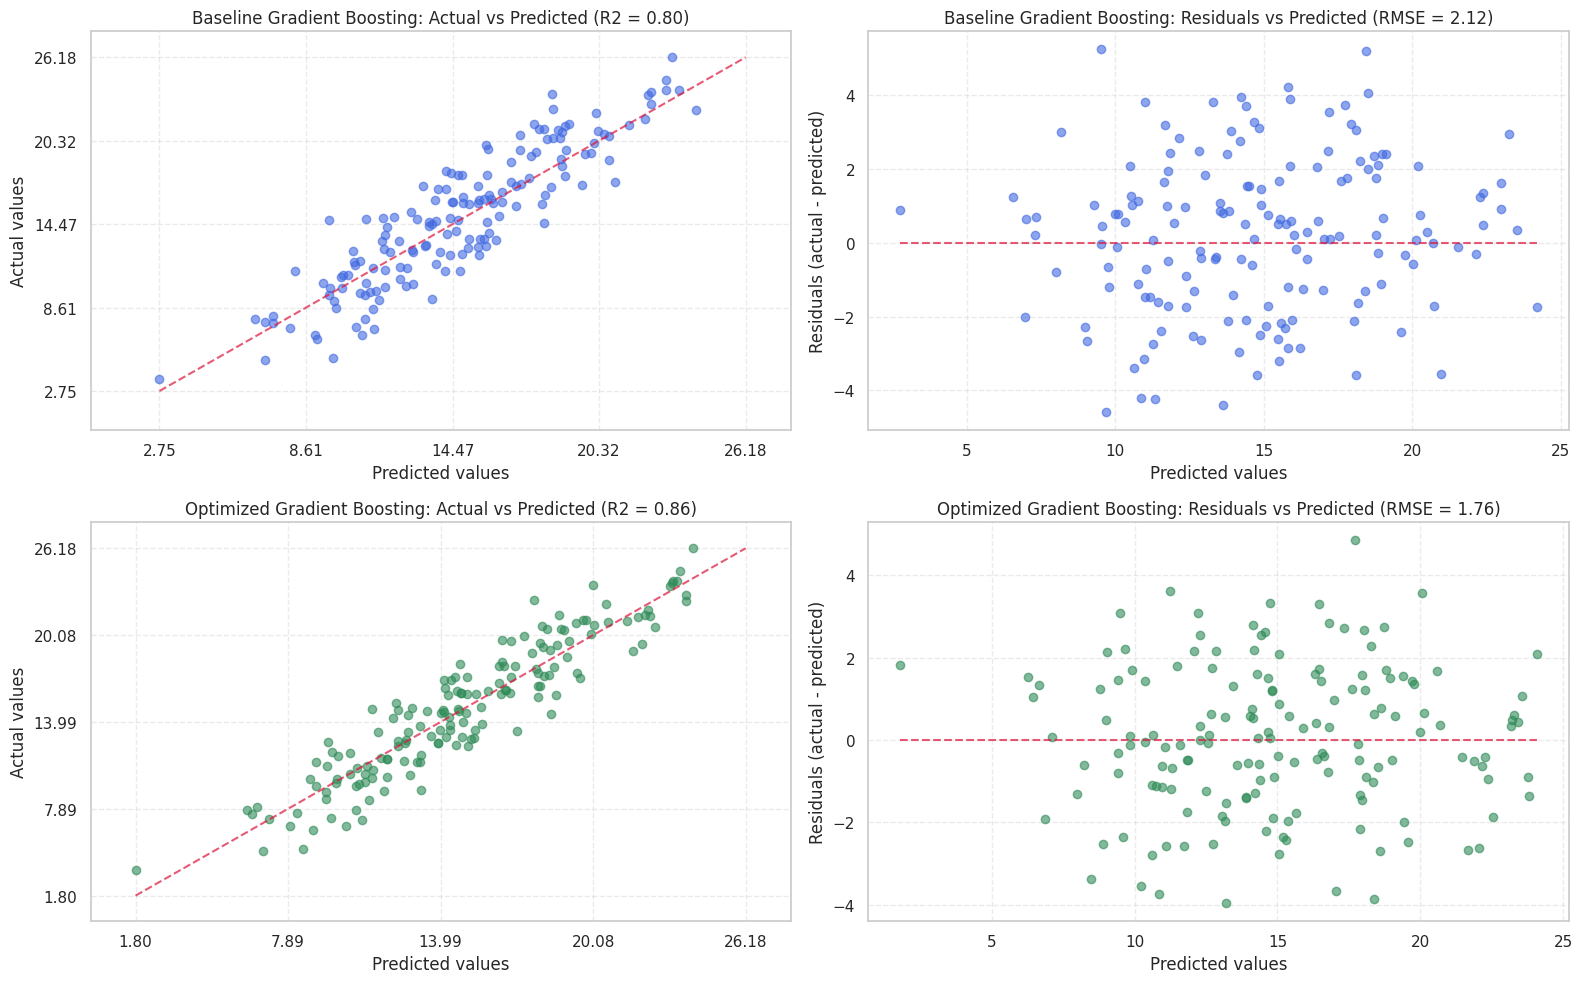

In [41]:
# Select the best model based on lowest RWSE
best_model_name = result_df.loc[0, "Model"]
best_y_pred = predictions[best_model_name]

# Aspects of each subplot
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
((ax1, ax2), (ax3, ax4)) = axes

# Subplot 1: Actual vs Predicted Values (Baseline Model)
PredictionErrorDisplay.from_predictions(
    y_true=y_test,
    y_pred=best_y_pred,
    kind="actual_vs_predicted",
    ax=ax1,
    scatter_kwargs={"alpha": 0.6, "color": "royalblue"},
    line_kwargs={"color": "crimson", "linestyle": "--"}
)

# Configurations Subplot 1
ax1.set_title(f"Baseline {best_model_name}: Actual vs Predicted (R2 = 0.80)")
ax1.grid(True, linestyle="--", alpha=0.4)



# Subplot 2: Residuals vs Predicted values (Baseline Model)
PredictionErrorDisplay.from_predictions(
    y_true=y_test,
    y_pred=best_y_pred,
    kind="residual_vs_predicted",
    ax=ax2,
    scatter_kwargs={"alpha": 0.6, "color": "royalblue"},
    line_kwargs={"color": "crimson", "linestyle": "--"}
)

# Configurations Subplot 2
ax2.set_title(f"Baseline {best_model_name}: Residuals vs Predicted (RMSE = 2.12)")
ax2.grid(True, linestyle="--", alpha=0.4)



# Subplot 3: Actual vs Predicted Values (Optimized Model)
PredictionErrorDisplay.from_predictions(
    y_true=y_test,
    y_pred=opt_test_preds,
    kind="actual_vs_predicted",
    ax=ax3,
    scatter_kwargs={"alpha": 0.6, "color": "seagreen"},
    line_kwargs={"color": "crimson", "linestyle": "--"}
)

# Configurations Subplot 3
ax3.set_title("Optimized Gradient Boosting: Actual vs Predicted (R2 = 0.86)")
ax3.grid(True, linestyle="--", alpha=0.4)



# Subplot 4: Residuals vs Predicted values (Optimized Model)
PredictionErrorDisplay.from_predictions(
    y_true=y_test,
    y_pred=opt_test_preds,
    kind="residual_vs_predicted",
    ax=ax4,
    scatter_kwargs={"alpha": 0.6, "color": "seagreen"},
    line_kwargs={"color": "crimson", "linestyle": "--"}
)

# Configurations Subplot 4
ax4.set_title("Optimized Gradient Boosting: Residuals vs Predicted (RMSE = 1.76)")
ax4.grid(True, linestyle="--", alpha=0.4)

# Identical axis limits
for ax in (ax1, ax3):
  ax.set_aspect("auto")
  ax.set_xlim(0, 28)
  ax.set_ylim(0, 28)

# Display chart
plt.tight_layout()
plt.show()

## Predicted vs Actual by feature

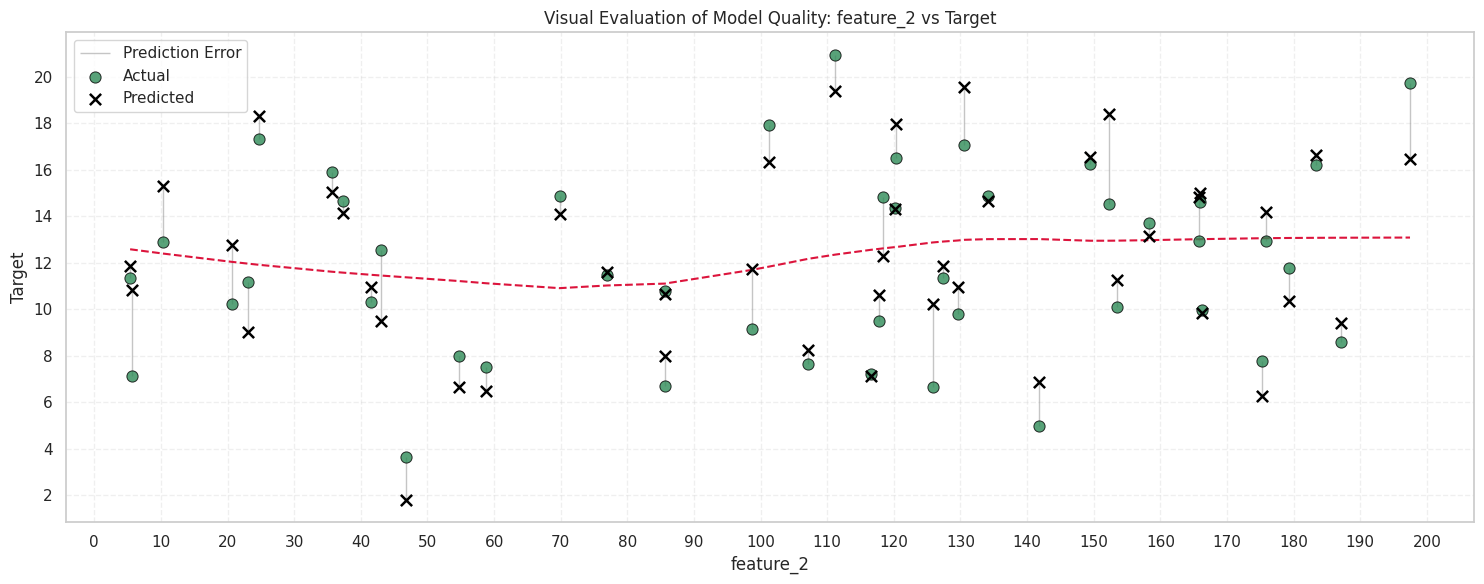

In [48]:
# The main predictive feature
main_feature = "feature_2"

# Specific window to analyze for the feature
bottom_mask = 0
top_mask = 200
mask = (X_test_top5[main_feature] >= bottom_mask) & (X_test_top5[main_feature] <= top_mask)
x_zoom = X_test_top5.loc[mask, main_feature]
y_actual_zoom = y_test[mask]
y_pred_zoom = opt_test_preds[mask]


# Char aspects
plt.figure(figsize=(15, 6))

# Draw vertical error lines
plt.vlines(x=x_zoom, ymin=y_actual_zoom, ymax=y_pred_zoom, color="gray", alpha=0.45, linestyle="-", linewidth=1, label="Prediction Error")

# Plot Actual values (circles)
plt.scatter(
    x_zoom, y_actual_zoom,
    color="seagreen", alpha=0.8, s=65, edgecolors="black", linewidth=0.7,
    label="Actual", zorder=3
)

# Plot Predicted values ('X' markers)
plt.scatter(
    x_zoom, y_pred_zoom,
    color="black", marker="x", s=65, linewidths=1.8,
    label="Predicted", zorder=4
)

# Smooth trend line of the predicition
sns.regplot(
    x=x_zoom, y=y_pred_zoom,
    scatter=False, lowess=True,
    line_kws={"color": "crimson", "linestyle": "--", "linewidth": 1.5, "label": "Trend"}
)

# Add granular ticks on both X-xis every 10 units and Y-axis every 2 units
ax = plt.gca()
ax.xaxis.set_major_locator(ticker.MultipleLocator(10))
ax.yaxis.set_major_locator(ticker.MultipleLocator(2))

# Char styling
plt.title(f"Visual Evaluation of Model Quality: {main_feature} vs Target")
plt.xlabel(main_feature)
plt.ylabel("Target")
plt.legend(loc="upper left", frameon=True)
plt.grid(True, linestyle="--", alpha=0.3)

# Display chart
plt.tight_layout()
plt.show()

# Final Training & Inference

Con los parámetros óptimos pasamos a entrenar el modelo con el 100% de los datos y a realizar predicciones finales

## Model Training Final

In [52]:
# Use 100% of df_train using only the Top 5 features
X_full_top5 = df_train[top_5_features]
y_full = df_train["target"]
df_test_top5 = df_test[top_5_features]

# Initialize and train model with the best hyperparams
final_model = GradientBoostingRegressor(
    learning_rate=0.1,
    max_depth=2,
    min_samples_leaf=10,
    n_estimators=300,
    subsample=0.8,
    random_state=42
)
final_model.fit(X_full_top5, y_full)

# Generate predictions
final_predictions = final_model.predict(df_test_top5)

# Create result Dataframe
result_df = pd.DataFrame({
    "id": df_test.index,
    "predicted_target": final_predictions
})

# Show diagnosis
print("--- FINAL INFERENCE COMPLETED ---")
display(result_df.head(10))

print("\nSummary statistics of predicted_target:")
print(result_df["predicted_target"].describe())

# Export the predictions to CSV and download
result_df.to_csv("final_predictions.csv", index=False)
files.download("final_predictions.csv")

--- FINAL INFERENCE COMPLETED ---


,id,predicted_target
0,0,12.931617
1,1,11.803905
2,2,15.523249
3,3,12.711022
4,4,17.296687
5,5,11.029094
6,6,19.134304
7,7,17.960839
8,8,11.750599
9,9,8.834551



Summary statistics of predicted_target:
count    200.000000
mean      14.203521
std        4.898400
min        1.990210
25%       10.431477
50%       14.578868
75%       17.530976
max       25.573848
Name: predicted_target, dtype: float64


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>